# Stro-7 module score, transferred from human to mouse through the SAMap graph

Each mouse fibroblast/decidual cell gets the mean of its human neighbors' `Ulrich2024_sg_Stro7_top50`, weighted by the
SAMap graph (`obsp['connectivities']` of the SAMap object of record). `transfer()` is copied unchanged from
`stro7_cosine/stro7_cosine.ipynb`; it is the operator that carries pseudotime from mouse to human, run the other way.

Reads the SAMap object and Ç. Cevrim's human and mouse fib/dec objects; writes one CSV (one row per mouse cell) and its
provenance into `OUT`, a new folder. Nothing else is written.


In [1]:
# Parameters (papermill -p NAME VALUE overrides them)
D = "/n/lab_storage/eddy_lab/Lab/mckinley/data"
SAMAP = f"{D}/20261113_samap_final_ensembl_ids.h5ad"  # same file as the run of record's 3_transfer/Samap_Final.h5ad
HUMAN = f"{D}/20261111_Human_only_eFib_dec_final.h5ad"  # holds the score
MOUSE = f"{D}/20261111_mouse_only_eFib_dec_final.h5ad"  # for the mouse subtypes in the check below
SCORE = "Ulrich2024_sg_Stro7_top50"
OUT = "./stro7_top50_20261113"  # a new folder for the CSV


In [2]:
import datetime
import hashlib
import json
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
from anndata.io import read_elem

OUT = Path(OUT)
assert OUT.name and not OUT.exists(), "set OUT to a new folder"


def read_obs(path):
    with h5py.File(path, "r") as handle:
        obs = read_elem(handle["obs"])
    obs.index = obs.index.astype(str)
    return obs


with h5py.File(SAMAP, "r") as handle:
    connectivities = read_elem(handle["obsp"]["connectivities"]).tocsr()
obs = read_obs(SAMAP)
human, mouse = read_obs(HUMAN), read_obs(MOUSE)
assert connectivities.shape == (len(obs), len(obs))

is_human = obs["species"].astype(str).isin(["hs", "human"]).to_numpy()
is_mouse = obs["species"].astype(str).isin(["mm", "mouse"]).to_numpy()
assert set(obs.index[is_human]) == set(human.index) and set(obs.index[is_mouse]) == set(mouse.index)
values = human[SCORE].reindex(obs.index).to_numpy(float)  # NaN on the mouse cells
print(f"SAMap graph: {is_human.sum():,} human nuclei, {is_mouse.sum():,} mouse cells")
print(f"{SCORE}: {np.isfinite(values[is_human]).sum():,} human nuclei with a value")


SAMap graph: 46,818 human nuclei, 42,966 mouse cells
Ulrich2024_sg_Stro7_top50: 46,818 human nuclei with a value


## Transfer

In [3]:
def transfer(graph, values, is_source):
    """Each cell's connectivity-weighted mean of its source neighbors' values; NaN without a source neighbor."""
    has_value = is_source & np.isfinite(values)
    weighted_sum = graph.dot(np.where(has_value, values, 0.0))
    weight = graph.dot(has_value.astype(float))
    mean = np.full(graph.shape[0], np.nan)
    mean[weight > 0] = weighted_sum[weight > 0] / weight[weight > 0]
    return mean


transferred = pd.Series(transfer(connectivities, values, is_human)[is_mouse], index=obs.index[is_mouse],
                        name=f"{SCORE}_transferred")
print(f"mouse cells {len(transferred):,} | without a human neighbor {int(transferred.isna().sum())}")


mouse cells 42,966 | without a human neighbor 1


## Check by eye

The score by subtype: human (as stored) and mouse (transferred). In the C7-fibroblast analysis, Stro-7 mapped to the
mouse outer fibroblasts (eFib1).

In [4]:
print(human.groupby("cell_subtype", observed=True)[SCORE].median().round(3).to_string())
print()
mouse_subtype = mouse["cell_subtype"].reindex(transferred.index)
print(transferred.groupby(mouse_subtype, observed=True).median().round(3).to_string())


cell_subtype
dec1      0.198
dec2      0.097
decAp1    0.017
decAp2    0.026
eFib1     0.337
eFib2     0.222
eFib3     0.176
eFib4     0.128

cell_subtype
eFib1     0.433
eFib2     0.143
eFib2i    0.203
eFib3     0.116
eFibP     0.153
dec1      0.175
dec2      0.114
dec3      0.053
decAp     0.219


## On the sections

Positioned cells of each section (`obs['timepoint']`; a section's lanes together) colored by the score: as stored on
the human sections, transferred on the mouse ones (one color scale per species, 1st to 99th percentile).

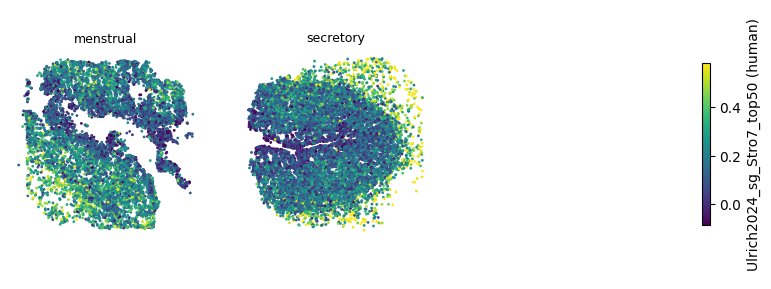

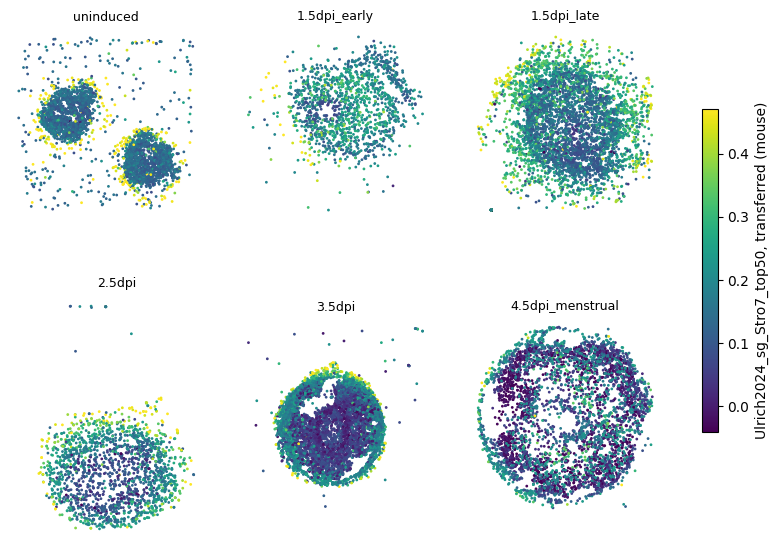

In [5]:
import matplotlib.pyplot as plt


def plot_sections(cells, values, label, ncols=3):
    """One panel per section (obs timepoint): the positioned cells colored by values, on one color scale."""
    cells = cells.assign(value=values).dropna(subset=["x_um_dbscan", "y_um_dbscan", "value"])
    sections = [t for t in pd.Categorical(cells["timepoint"]).categories if (cells["timepoint"] == t).any()]
    vmin, vmax = np.percentile(cells["value"], [1, 99])
    nrows = -(-len(sections) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 3.5 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, section in zip(axes.flat, sections):
        cells_here = cells[cells["timepoint"] == section]
        dots = ax.scatter(cells_here["x_um_dbscan"], cells_here["y_um_dbscan"], c=cells_here["value"], s=1,
                          cmap="viridis", vmin=vmin, vmax=vmax)
        ax.set_aspect("equal")
        ax.set_title(section, fontsize=9)
    fig.colorbar(dots, ax=axes, shrink=0.6, label=label)
    plt.show()


plot_sections(human, human[SCORE], f"{SCORE} (human)")
plot_sections(mouse, transferred.reindex(mouse.index), f"{SCORE}, transferred (mouse)")


## Output

In [6]:
def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()


OUT.mkdir(parents=True)
csv = OUT / f"{SCORE}_transferred_mouse.csv"
transferred.to_csv(csv, index_label="cell")
provenance = {"written": datetime.datetime.now().isoformat(timespec="seconds"), "score": SCORE,
              "inputs": {path: sha256(path) for path in (SAMAP, HUMAN, MOUSE)},
              "mouse_cells": len(transferred), "with_a_value": int(transferred.notna().sum()),
              "output": {str(csv): sha256(csv)}}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=1))
print("wrote", csv)


wrote stro7_top50_20261113/Ulrich2024_sg_Stro7_top50_transferred_mouse.csv
